<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 0. Settings
Paths, imports, session lists. usable = 63 sessions that were preprocessed; final = 60 sessions used in the analysis (from 01_sessions_setup).
Tables -> main\tables, figures -> main\figures\02_preprocessing, copies for the project -> data\amir_data.

<div>

In [1]:
# %%
# ── 0. SETTINGS ──
import os, re, glob, json, shutil, time, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spikeinterface.full as si

DATA_ROOT = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data"
RAW    = os.path.join(DATA_ROOT, "0_raw")
PROC   = os.path.join(DATA_ROOT, "2_processed")
AMIR   = os.path.join(DATA_ROOT, "amir_data")
TABLES = r"C:\Users\ar687\Documents\GitHub\AmirAnalysis\main\tables"
FIGS   = os.path.join(os.path.dirname(TABLES), "figures", "02_preprocessing")
SUB    = os.path.join("amir_data", "down_sampled", "1000_Hz")       # 1000 Hz folder inside each session
pilot  = "20260522_r0000136_wt_1750"                                 # old pilot, made by hand (no DONE.txt)
os.makedirs(FIGS, exist_ok=True); os.makedirs(AMIR, exist_ok=True)

load = getattr(si, "load", None) or si.load_extractor                # si.load (0.105) / si.load_extractor (older)
usable = pd.read_csv(os.path.join(TABLES, "usable_sessions.csv"), dtype={"rat": str})
final  = pd.read_csv(os.path.join(TABLES, "final_sessions.csv"), dtype={"rat": str})
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

print(f"SpikeInterface {si.__version__} | usable (preprocessed): {len(usable)} | final (analysed): {len(final)}")
assert all(os.path.isdir(p) for p in [RAW, PROC, TABLES]), "a path is wrong"

SpikeInterface 0.105.0 | usable (preprocessed): 63 | final (analysed): 60


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 1. Preprocessing of all usable sessions (downsampling: done 2026-10-16, 24.6 h)
Code exactly as it was run (SpikeInterface 0.105.0, n_jobs=4, chunk 5 s after an out-of-memory crash with 22 jobs).
Each session: raw ap.bin → bandpass 1–300 Hz → detect_bad_channels + remove → phase_shift → notch 50 Hz (q=30) → resample 1000 Hz
→ saved un-referenced to 2_processed\<session>\amir_data\down_sampled\1000_Hz, DONE.txt at the end.
Exception: the old pilot 20260522_r0000136_wt_1750 was processed earlier by hand with the same chain (SpikeInterface 0.104.8, chunk 1 s),
so it has no DONE.txt; it also has an extra 1000_Hz_CAR folder (pilot only).

```python
import os, glob, time, shutil
from pathlib import Path
import pandas as pd
import spikeinterface.full as si

DATA_ROOT = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data"
RAW   = os.path.join(DATA_ROOT, "0_raw")
PROC  = os.path.join(DATA_ROOT, "2_processed")
pilot = "20260522_r0000136_wt_1750"

usable = pd.read_csv("usable_sessions.csv")          # 63 sessions
N_JOBS = 4         # was: max(1, os.cpu_count() - 2)
CHUNK  = "5s"      # was: "10s"
SUB    = Path("amir_data") / "down_sampled" / "1000_Hz"
LOG    = Path("preprocessing_log.csv")

def preprocess_session(s):
    out = Path(PROC) / s / SUB
    done = out / "DONE.txt"
    if done.exists() or (s == pilot and out.exists()):     # pilot already made with the same chain
        return None
    if out.exists():                                        # half-finished from a crash -> redo
        shutil.rmtree(out)
    ap_bin = glob.glob(os.path.join(RAW, s, "**", "*.ap.bin"), recursive=True)[0]
    t0 = time.time()
    raw  = si.read_spikeglx(Path(ap_bin).parent, stream_name="imec0.ap")
    rec1 = si.bandpass_filter(raw, freq_min=1.0, freq_max=300, dtype="float32", ignore_low_freq_error=True)
    bad, labels = si.detect_bad_channels(rec1)
    rec2 = rec1.remove_channels(bad)
    rec3 = si.phase_shift(rec2)
    rec4 = si.notch_filter(rec3, freq=50, q=30)
    rec5 = si.resample(rec4, resample_rate=1000)
    rec5.save(folder=out, n_jobs=N_JOBS, chunk_duration=CHUNK, progress_bar=True)
    done.write_text("ok")
    return {"session": s, "minutes": round((time.time() - t0) / 60, 1),
            "n_bad": len(bad), "bad_ids": " ".join(map(str, bad)),
            "labels": str(pd.Series(labels).value_counts().to_dict()),
            "n_channels_kept": rec5.get_num_channels()}

for i, s in enumerate(usable["session"], 1):
    row = preprocess_session(s)          # errors were caught and written to preprocessing_errors.csv
    if row is not None:
        pd.DataFrame([row]).to_csv(LOG, mode="a", header=not LOG.exists(), index=False)
```

The code cell below is the same chain with a RUN switch (RUN = False: it only reports, nothing is processed).

<div>

In [2]:
# %%
# ── 1. PREPROCESS ALL USABLE SESSIONS -> un-referenced 1000 Hz ──
RUN    = False                                   # True only to process NEW sessions
N_JOBS = 4                                       # was max(1, os.cpu_count() - 2): out-of-memory crash
CHUNK  = "5s"                                    # was "10s"
RUN_LOG = os.path.join(TABLES, "preprocessing_run_log.csv")      # only written if RUN = True
ERR_LOG = os.path.join(TABLES, "preprocessing_errors.csv")

def preprocess_session(s):
    out = Path(PROC) / s / SUB
    done = out / "DONE.txt"
    if done.exists() or (s == pilot and out.exists()):     # pilot already made with the same chain
        return None
    if out.exists():                                        # half-finished from a crash -> redo
        shutil.rmtree(out)
    ap_bin = glob.glob(os.path.join(RAW, s, "**", "*.ap.bin"), recursive=True)[0]
    t0 = time.time()
    raw  = si.read_spikeglx(Path(ap_bin).parent, stream_name="imec0.ap")
    rec1 = si.bandpass_filter(raw, freq_min=1.0, freq_max=300, dtype="float32", ignore_low_freq_error=True)
    bad, labels = si.detect_bad_channels(rec1)
    rec2 = rec1.remove_channels(bad)
    rec3 = si.phase_shift(rec2)
    rec4 = si.notch_filter(rec3, freq=50, q=30)
    rec5 = si.resample(rec4, resample_rate=1000)
    rec5.save(folder=out, n_jobs=N_JOBS, chunk_duration=CHUNK, progress_bar=True)
    done.write_text("ok")
    return {"session": s, "minutes": round((time.time() - t0) / 60, 1),
            "n_bad": len(bad), "bad_ids": " ".join(map(str, bad)),
            "labels": str(pd.Series(labels).value_counts().to_dict()),
            "n_channels_kept": rec5.get_num_channels()}

todo = [s for s in usable["session"]
        if not (os.path.exists(os.path.join(PROC, s, SUB, "DONE.txt")) or (s == pilot and os.path.isdir(os.path.join(PROC, s, SUB))))]
print(f"usable: {len(usable)} | already done: {len(usable) - len(todo)} | still to do: {len(todo)} {todo}")

if RUN and todo:
    t_all = time.time()
    for i, s in enumerate(todo, 1):
        print(f"\n[{i}/{len(todo)}] {s}", flush=True)
        try:
            row = preprocess_session(s)
        except Exception as e:                              # one broken session does not stop the run
            print(f"  ERROR: {e}")
            pd.DataFrame([{"session": s, "error": str(e)}]).to_csv(
                ERR_LOG, mode="a", header=not os.path.exists(ERR_LOG), index=False)
            continue
        print(f"  {row['minutes']} min | bad: {row['n_bad']} {row['bad_ids']} | {row['labels']}", flush=True)
        pd.DataFrame([row]).to_csv(RUN_LOG, mode="a", header=not os.path.exists(RUN_LOG), index=False)
    print(f"\nFinished in {(time.time() - t_all) / 3600:.1f} h")
else:
    print("RUN = False -> nothing processed" if todo else "all usable sessions are preprocessed")

usable: 63 | already done: 63 | still to do: 0 []
all usable sessions are preprocessed


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 2. Bad channels per session (log rebuilt from the saved recordings)
The original preprocessing_log.csv was lost (2026-10-16). Rebuilt here: bad channels = AP0–AP383 minus the channels kept in each
saved 1000 Hz recording (= the channels detect_bad_channels removed). All 63 usable (preprocessed) sessions.
Saved: tables\preprocessing_log.csv (session, rat, n_bad, bad_ids, n_channels_kept).
RESULT 2026-10-16: rat 134 7–9 bad channels, rat 135 6–8, rat 136 1 (AP138).

<div>

In [4]:
# %%
# ── 2. BAD CHANNELS PER SESSION, rebuilt from the saved 1000 Hz recordings ──
ALL = [f"AP{i}" for i in range(384)]
rows = []
for _, u in usable.iterrows():
    s = u["session"]
    try:
        rec = load(os.path.join(PROC, s, SUB))                 # only reads metadata, not the traces
        kept_ids = [str(c) for c in rec.get_channel_ids()]
        kept = {m.group(0) for c in kept_ids if (m := re.search(r"AP\d+", c))}
        bad = sorted(set(ALL) - kept, key=lambda c: int(c[2:]))
        rows.append({"session": s, "rat": u["rat"], "n_bad": len(bad), "bad_ids": ";".join(bad),
                     "n_channels_kept": len(kept_ids), "example_id": kept_ids[0]})
    except Exception as e:
        rows.append({"session": s, "rat": u["rat"], "error": repr(e)})
log = pd.DataFrame(rows)

print("sessions read:", log["n_bad"].notna().sum(), "/", len(log))
if "error" in log:
    print("errors:"); print(log.loc[log["error"].notna(), ["session", "error"]].to_string(index=False))
print("example channel id as stored:", log["example_id"].dropna().iat[0])
print("kept + bad == 384 in every session:", ((log["n_bad"] + log["n_channels_kept"]) == 384).all())
print(log.groupby("rat")["n_bad"].agg(["min", "max"]))
log.drop(columns=["example_id"]).to_csv(os.path.join(TABLES, "preprocessing_log.csv"), index=False)
print("saved -> tables\\preprocessing_log.csv")

sessions read: 63 / 63
example channel id as stored: imec0.ap#AP0
kept + bad == 384 in every session: True
     min  max
rat          
134    7    9
135    6    8
136    1    1
saved -> tables\preprocessing_log.csv


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 3. Bad channels per rat (final sessions)
From preprocessing_log.csv (step 2), only the 60 final sessions: how often each channel was removed by detect_bad_channels,
and which bad-channel lists occur per rat. Figure: top = % of sessions a channel is bad; bottom = session × channel (black = bad).
RESULT 2026-10-16 (63 sessions): rat 134 core AP27, AP64, AP89, AP179, AP187, AP303, AP332 (+AP63, AP90 in some);
rat 135 core AP132, AP193, AP322, AP325, AP329, AP376 (+AP326, AP362 in some); rat 136 AP138 only.
Saved: tables\bad_channel_frequency.csv, figures\02_preprocessing\bad_channels_per_rat.png.

<div>

final sessions in the log: 60  (expected 60)
parsed count == n_bad in every session: True

how often each channel is bad:
rat channel  n_sessions_bad  n_sessions_rat  percent
134    AP27              11              11    100.0
134    AP64              11              11    100.0
134    AP89              11              11    100.0
134   AP179              11              11    100.0
134   AP187              11              11    100.0
134   AP303              11              11    100.0
134   AP332              11              11    100.0
134    AP90               5              11     45.5
134    AP63               1              11      9.1
135   AP132              29              29    100.0
135   AP193              29              29    100.0
135   AP322              29              29    100.0
135   AP325              29              29    100.0
135   AP329              29              29    100.0
135   AP376              29              29    100.0
135   AP326              23   

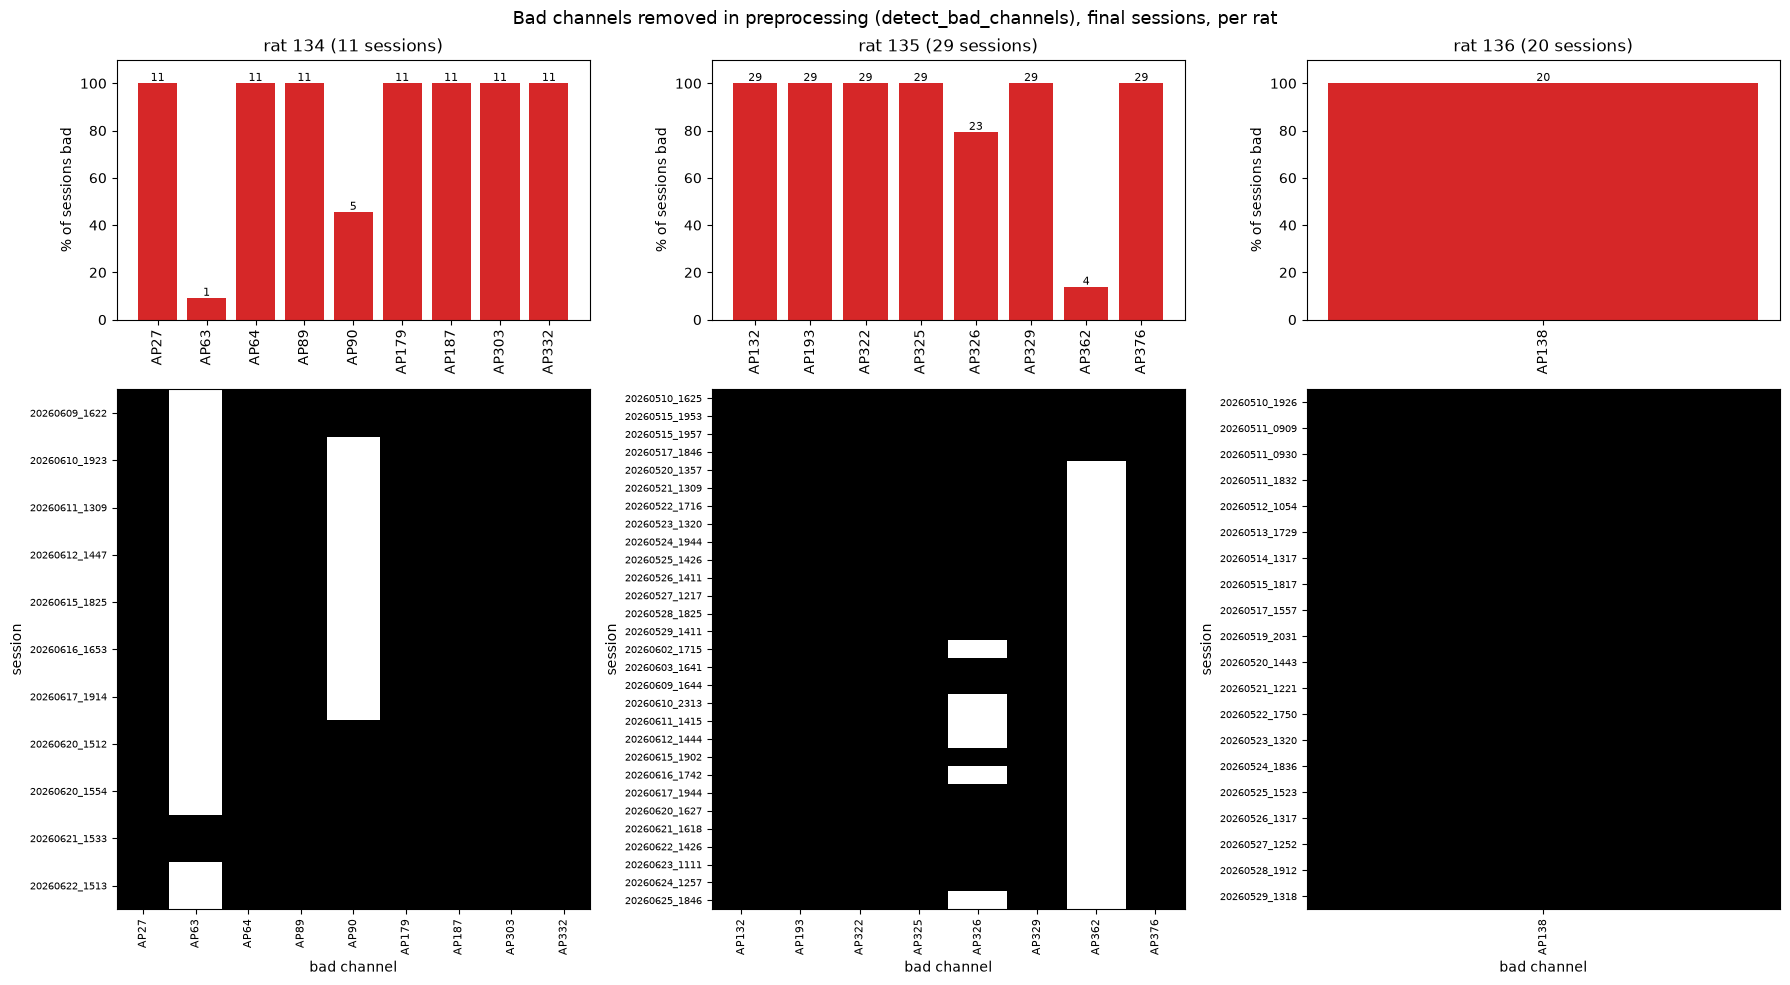

In [6]:
# %%
# ── 3. BAD CHANNELS PER RAT: how often is each channel bad, and are the lists the same? (final sessions) ──
log = pd.read_csv(os.path.join(TABLES, "preprocessing_log.csv"), dtype={"rat": str})
check = log[log["session"].isin(final["session"])].copy()
print(f"final sessions in the log: {len(check)}  (expected 60)")

num = lambda c: int(re.sub(r"\D", "", c))
check["bad_list"] = check["bad_ids"].fillna("").apply(lambda x: [c for c in x.split(";") if c])
print("parsed count == n_bad in every session:", (check["bad_list"].str.len() == check["n_bad"]).all())

n_sess = check.groupby("rat")["session"].nunique()
long = (check[["rat", "session", "bad_list"]].explode("bad_list")
          .dropna(subset=["bad_list"]).rename(columns={"bad_list": "channel"}))
freq = long.groupby(["rat", "channel"]).size().rename("n_sessions_bad").reset_index()
freq["n_sessions_rat"] = freq["rat"].map(n_sess)
freq["percent"] = (100 * freq["n_sessions_bad"] / freq["n_sessions_rat"]).round(1)
freq["chan_num"] = freq["channel"].apply(num)
freq = freq.sort_values(["rat", "n_sessions_bad", "chan_num"], ascending=[True, False, True])
print("\nhow often each channel is bad:")
print(freq.drop(columns="chan_num").to_string(index=False))
freq.drop(columns="chan_num").to_csv(os.path.join(TABLES, "bad_channel_frequency.csv"), index=False)

check["bad_set"] = check["bad_list"].apply(lambda l: ", ".join(sorted(l, key=num)) or "(none)")
print("\nidentical bad-channel lists per rat (number of sessions):")
print(check.groupby(["rat", "bad_set"]).size().to_string())

# figure: top = % of sessions each channel is bad; bottom = session x channel (black = bad)
rats = sorted(check["rat"].unique())
fig, axes = plt.subplots(2, len(rats), figsize=(6 * len(rats), 10),
                         gridspec_kw={"height_ratios": [1, 2]}, squeeze=False)
for j, rat in enumerate(rats):
    f = freq[freq["rat"] == rat].sort_values("chan_num")
    c = check[check["rat"] == rat].sort_values("session")
    ax = axes[0, j]
    ax.set_title(f"rat {rat} ({n_sess[rat]} sessions)")
    if f.empty:
        ax.text(0.5, 0.5, "no bad channels", ha="center", transform=ax.transAxes); axes[1, j].axis("off"); continue
    ax.bar(f["channel"], f["percent"], color="tab:red")
    for x, (p, n) in enumerate(zip(f["percent"], f["n_sessions_bad"])):
        ax.text(x, p + 1, str(n), ha="center", fontsize=8)          # number of sessions above each bar
    ax.set_ylim(0, 110); ax.set_ylabel("% of sessions bad"); ax.tick_params(axis="x", rotation=90)
    M = np.array([[ch in l for ch in f["channel"]] for l in c["bad_list"]], dtype=int)
    ax = axes[1, j]
    ax.imshow(M, aspect="auto", cmap="Greys", vmin=0, vmax=1, interpolation="nearest")
    ax.set_xticks(range(len(f))); ax.set_xticklabels(f["channel"], rotation=90, fontsize=8)
    ax.set_yticks(range(len(c)))
    ax.set_yticklabels(c["session"].str[:8] + "_" + c["session"].str[-4:], fontsize=7)
    ax.set_xlabel("bad channel"); ax.set_ylabel("session")
fig.suptitle("Bad channels removed in preprocessing (detect_bad_channels), final sessions, per rat", fontsize=13)
fig.tight_layout()
fig.savefig(os.path.join(FIGS, "bad_channels_per_rat.png"), dpi=150)
fig.savefig(os.path.join(AMIR, "dead_channels.png"), dpi=150)
plt.show()

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 4. All excluded channels per session (preprocessing + found later), final sessions
Preprocessing: detect_bad_channels (step 2). Later: extra_bad_channels.csv (signal QC per session, plus per-rat hardware channels
AP326 + AP362 in rat 135, AP63 + AP90 in rat 134, excluded in all sessions of that rat).
Total = union of both lists (a channel in both is counted once). Channels used = 384 − total.
Saved: tables\excluded_channels_per_session.csv.

<div>

In [7]:
# %%
# ── 4. ALL EXCLUDED CHANNELS PER SESSION: preprocessing + found later (final sessions) ──
XB = pd.read_csv(os.path.join(TABLES, "extra_bad_channels.csv"))
XB["channel"] = XB["channel_id"].astype(str).str.extract(r"(AP\d+)")[0]
later = XB.groupby("session")["channel"].apply(set)

rows = []
for _, r in check.iterrows():                                     # check = final sessions from step 3
    pre = set(r["bad_list"])
    lat = later.get(r["session"], set())
    rows.append({"session": r["session"], "rat": r["rat"],
                 "n_preproc": len(pre), "n_later": len(lat),
                 "n_later_already_preproc": len(lat & pre),        # found later but already removed
                 "n_total": len(pre | lat), "n_used": 384 - len(pre | lat),
                 "later_ids": ";".join(sorted(lat - pre, key=num))})
EXC = pd.DataFrame(rows)
EXC.to_csv(os.path.join(TABLES, "excluded_channels_per_session.csv"), index=False)

print("per rat, per session: median [min–max]")
for rat, d in EXC.groupby("rat"):
    f = lambda c: f"{d[c].median():.0f} [{d[c].min()}–{d[c].max()}]"
    print(f"  rat {rat}: {len(d)} sessions | preprocessing {f('n_preproc')} | later {f('n_later')} "
          f"| total {f('n_total')} | used {f('n_used')} of 384")
print("\nlater-found channels that were already removed in preprocessing:", int(EXC["n_later_already_preproc"].sum()))
print("\nlater-found channels (final sessions) by rat and channel:")
XBf = XB[XB["session"].isin(final["session"])].merge(final[["session", "rat"]], on="session")
print(XBf.groupby(["rat", "channel"]).size().to_string())
print("\nsessions in extra_bad_channels.csv that are not final sessions:",
      sorted(set(XB["session"]) - set(final["session"])))

per rat, per session: median [min–max]
  rat 134: 11 sessions | preprocessing 7 [7–9] | later 2 [0–2] | total 9 [9–9] | used 375 [375–375] of 384
  rat 135: 29 sessions | preprocessing 7 [6–8] | later 1 [0–2] | total 8 [8–9] | used 376 [375–376] of 384
  rat 136: 20 sessions | preprocessing 1 [1–1] | later 0 [0–0] | total 1 [1–1] | used 383 [383–383] of 384

later-found channels that were already removed in preprocessing: 0

later-found channels (final sessions) by rat and channel:
rat  channel
134  AP63       10
     AP90        6
135  AP326       6
     AP362      25
     AP381       1

sessions in extra_bad_channels.csv that are not final sessions: ['20260623_r0000134_wt_1232', '20260624_r0000134_wt_1323', '20260625_r0000134_wt_1820']
